In [15]:
import yfinance as yf
import pandas as pd

tickers = ["AAPL", "MSFT", "NVDA", "AMZN", "GOOGL", "JNJ"]

data = yfinance_download = yf.download(tickers, start="2021-01-01", end="2026-01-01")["Close"]

w_series = pd.Series(w_star, index=mean_daily.index)   # align BY NAME
print(w_series.round(2))
print("max Sharpe:", round(ret_star / vol_star, 2))
print(f"optimized portfolio: {ret_star*100:.1f}% return, {vol_star*100:.1f}% vol")
data.tail()

[*********************100%***********************]  6 of 6 completed

Ticker
AAPL     0.00
AMZN     0.00
GOOGL    0.14
JNJ      0.55
MSFT     0.00
NVDA     0.31
dtype: float64
max Sharpe: 1.49
optimized portfolio: 30.3% return, 20.3% vol


Ticker,AAPL,AMZN,GOOGL,JNJ,MSFT,NVDA
Date,,,,,,
2025-12-24,273.066711,232.380005,313.480194,204.490891,484.943390,188.169678
2025-12-26,272.657867,232.520004,312.901337,204.343246,484.635345,190.085205
2025-12-29,273.016876,232.070007,312.951233,204.274368,484.029236,187.780594
2025-12-30,272.338684,232.529999,313.240662,203.634644,484.406860,187.102188
2025-12-31,271.122009,230.820007,312.392303,203.674026,480.571167,186.064606


In [2]:
# Daily % change. First row becomes NaN (no "yesterday" exists) — drop it.
returns = data.pct_change().dropna()

returns.head()

Ticker,AAPL,AMZN,GOOGL,JNJ,MSFT,NVDA
Date,,,,,,
2021-01-05,0.012364,0.010004,0.008064,0.011757,0.000965,0.022210
2021-01-06,-0.033662,-0.024897,-0.009868,0.009410,-0.025930,-0.058953
2021-01-07,0.034123,0.007577,0.029869,0.003378,0.028457,0.057830
2021-01-08,0.008631,0.006496,0.013239,-0.002058,0.006093,-0.005040
2021-01-11,-0.023249,-0.021519,-0.023106,-0.004187,-0.009699,0.025966


In [3]:
returns = data.pct_change().dropna()

returns.head()

Ticker,AAPL,AMZN,GOOGL,JNJ,MSFT,NVDA
Date,,,,,,
2021-01-05,0.012364,0.010004,0.008064,0.011757,0.000965,0.022210
2021-01-06,-0.033662,-0.024897,-0.009868,0.009410,-0.025930,-0.058953
2021-01-07,0.034123,0.007577,0.029869,0.003378,0.028457,0.057830
2021-01-08,0.008631,0.006496,0.013239,-0.002058,0.006093,-0.005040
2021-01-11,-0.023249,-0.021519,-0.023106,-0.004187,-0.009699,0.025966


In [5]:
summary = pd.DataFrame({
    "annual return %": returns.mean() * 252 * 100,          
    "annual vol %": returns.std() * (252 ** 0.5) * 100,
})
summary.round(1)

,annual return %,annual vol %
Ticker,,
AAPL,19.3,27.9
AMZN,13.6,35.1
GOOGL,30.9,31.1
JNJ,9.9,16.7
MSFT,20.2,25.7
NVDA,66.9,52.2


In [6]:
returns.corr().round(2)

Ticker,AAPL,AMZN,GOOGL,JNJ,MSFT,NVDA
Ticker,,,,,,
AAPL,1.00,0.56,0.58,0.15,0.63,0.52
AMZN,0.56,1.00,0.62,0.01,0.65,0.56
GOOGL,0.58,0.62,1.00,0.07,0.64,0.53
JNJ,0.15,0.01,0.07,1.00,0.08,-0.10
MSFT,0.63,0.65,0.64,0.08,1.00,0.63
NVDA,0.52,0.56,0.53,-0.10,0.63,1.00


In [7]:
import numpy as np
import matplotlib.pyplot as plt

n_portfolios = 10_000

mean_daily = returns.mean()          # 6 average daily returns
cov_daily = returns.cov()            # 6x6 "how do they move together" table

results = np.zeros((n_portfolios, 3))   # columns: return, risk, sharpe
weights_all = np.zeros((n_portfolios, 6))

for i in range(n_portfolios):
    w = np.random.random(6)          # 6 random numbers
    w = w / w.sum()                  # ...forced to add to 1 = a valid portfolio
    ret = (w @ mean_daily) * 252
    vol = np.sqrt(w @ cov_daily @ w) * np.sqrt(252)
    results[i] = [ret, vol, ret / vol]
    weights_all[i] = w

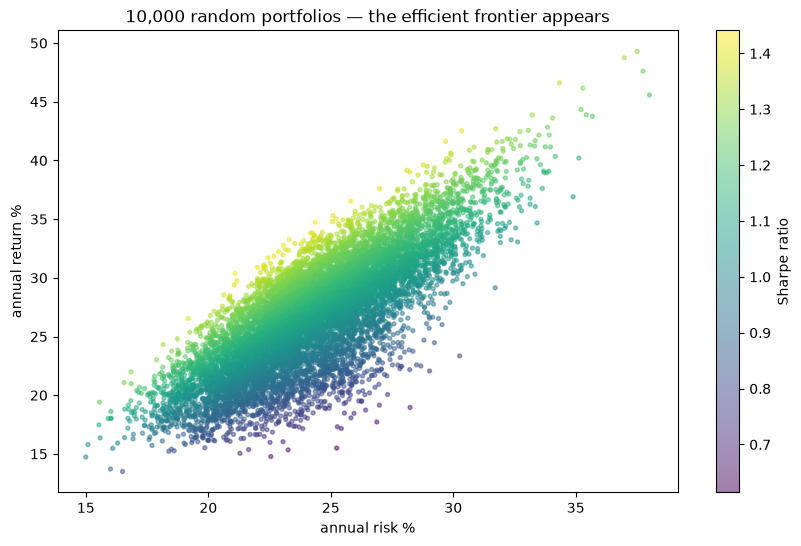

best Sharpe: 1.44
AAPL     0.03
MSFT     0.01
NVDA     0.26
AMZN     0.42
GOOGL    0.02
JNJ      0.26
dtype: float64


In [21]:
plt.figure(figsize=(10, 6))
sc = plt.scatter(results[:, 1] * 100, results[:, 0] * 100,
                 c=results[:, 2], cmap="viridis", s=8, alpha=0.5)
plt.colorbar(sc, label="Sharpe ratio")
plt.xlabel("annual risk %")
plt.ylabel("annual return %")
plt.title("10,000 random portfolios — the efficient frontier appears")
plt.savefig("images/efficient_frontier.png", dpi=150, bbox_inches="tight")
plt.show()

best = results[:, 2].argmax()
print("best Sharpe:", round(results[best, 2], 2))
print(pd.Series(weights_all[best], index=tickers).round(2))

In [11]:
pip install scipy

   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/37.4 MB ? eta -:--:--
    --------------------------------------- 0.8/37.4 MB 1.6 MB/s eta 0:00:23
   - -------------------------------------- 1.6/37.4 MB 2.3 MB/s eta 0:00:16
   - -------------------------------------- 1.8/37.4 MB 2.2 MB/s eta 0:00:17
   -- ------------------------------------- 2.6/37.4 MB 2.4 MB/s eta 0:00:15
   --- ------------------------------------ 3.4/37.4 MB 2.7 MB/s eta 0:00:13
   ---- ----------------------------------- 4.5/37.4 MB 3.0 MB/s eta 0:00:11
   ----- ---------------------------------- 5.5/37.4 MB 3.3 MB/s eta 0:00:10
   ------- -------------------------------- 6.6/37.4 MB 3.4 MB/s eta 0:00:09
   ------- -------------------------------- 7.3/37.4 MB 3.5 MB/s eta 0:00:09
   --------- ------------------------------ 8.7/37.4 MB 3.7 MB/s eta 0:00:08
   ---------- ------


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
from scipy.optimize import minimize

def portfolio_stats(w):
    ret = (w @ mean_daily) * 252
    vol = np.sqrt(w @ cov_daily @ w) * np.sqrt(252)
    return ret, vol

def neg_sharpe(w):
    ret, vol = portfolio_stats(w)
    return -ret / vol

bounds = [(0, 1)] * 6                      # no shorting, no leverage
cons = {'type': 'eq', 'fun': lambda w: w.sum() - 1}
w0 = np.ones(6) / 6

opt = minimize(neg_sharpe, w0, method='SLSQP', bounds=bounds, constraints=cons)
w_star = opt.x
ret_star, vol_star = portfolio_stats(w_star)

print(pd.Series(w_star, index=tickers).round(2))
print("max Sharpe:", round(ret_star / vol_star, 2))

AAPL     0.00
MSFT     0.00
NVDA     0.14
AMZN     0.55
GOOGL    0.00
JNJ      0.31
dtype: float64
max Sharpe: 1.49


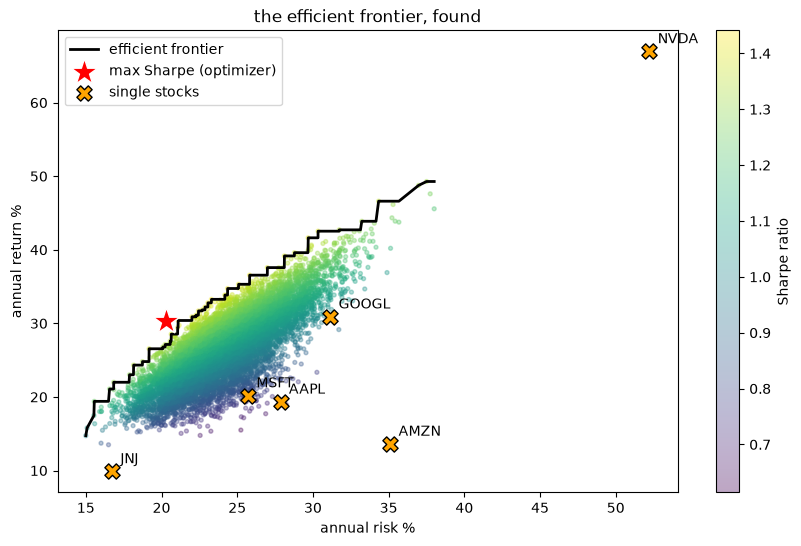

In [22]:
vols, rets = results[:, 1], results[:, 0]

# frontier line = best return seen at each risk level
order = np.argsort(vols)
sv, frontier = vols[order], np.maximum.accumulate(rets[order])

stock_ret = mean_daily * 252
stock_vol = returns.std() * np.sqrt(252)


plt.figure(figsize=(10, 6))
sc = plt.scatter(vols * 100, rets * 100, c=results[:, 2],
                 cmap="viridis", s=8, alpha=0.35)
plt.colorbar(sc, label="Sharpe ratio")
plt.plot(sv * 100, frontier * 100, color="black", linewidth=2,
         label="efficient frontier")
plt.scatter(vol_star * 100, ret_star * 100, marker="*", s=400, c="red",
            edgecolors="white", zorder=5, label="max Sharpe (optimizer)")
plt.scatter(stock_vol * 100, stock_ret * 100, marker="X", s=120,
            c="orange", edgecolors="black", zorder=5, label="single stocks")
for t in stock_vol.index:                              # iterate alphabetical names
    plt.annotate(t, (stock_vol[t] * 100, stock_ret[t] * 100),
                 textcoords="offset points", xytext=(6, 6), fontsize=10)
plt.xlabel("annual risk %"); plt.ylabel("annual return %")
plt.title("the efficient frontier, found")
plt.legend()
plt.savefig("images/efficient_frontier.png", dpi=150, bbox_inches="tight")
plt.show()

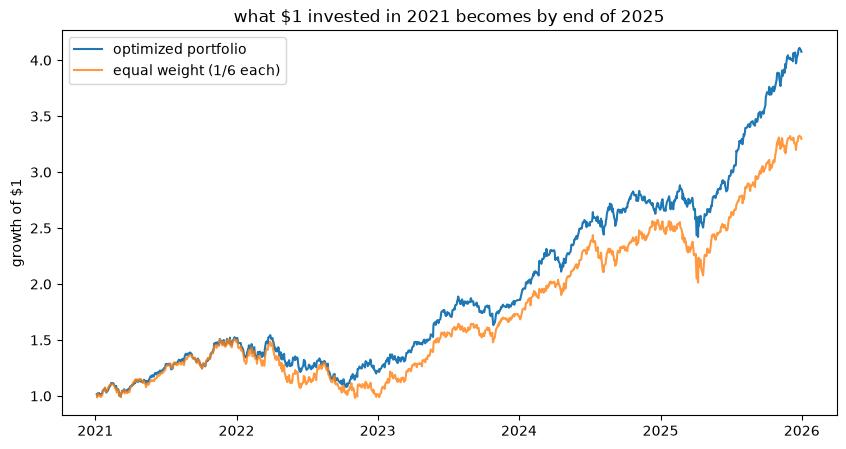

optimized:  $ 4.07
equal weight: $ 3.3


In [23]:
wealth_opt = (1 + (returns @ w_star)).cumprod()      # optimized portfolio
wealth_eq  = (1 + returns.mean(axis=1)).cumprod()    # equal weight, 1/6 each

plt.figure(figsize=(10, 5))
plt.plot(wealth_opt.index, wealth_opt, label="optimized portfolio")
plt.plot(wealth_eq.index, wealth_eq, label="equal weight (1/6 each)", alpha=0.8)
plt.ylabel("growth of $1")
plt.title("what $1 invested in 2021 becomes by end of 2025")
plt.legend()
plt.savefig("images/efficient_frontier.png", dpi=150, bbox_inches="tight")
plt.show()

print("optimized:  $", round(wealth_opt.iloc[-1], 2))
print("equal weight: $", round(wealth_eq.iloc[-1], 2))